# Corn store-or-sell: the whole process, step by step

**The question.** On **October 15**, should a Central Illinois corn holder **store the corn until April 15**,
hedged by selling May corn futures, or **sell now and put the cash in 6-month T-bills**? With the hedge in
place, storing pays only if the gap between May futures and the local cash price narrows by more than the
storage cost plus the T-bill interest given up. This notebook follows every step, from the raw files to an
out-of-sample test.

The question is framed for Central Illinois, and it is tested on **every region of six states** (IL, IA, NE, SD, MN, IN):
34 regions, 194 region-years, Country Elevators only.

**How to read it.** Every step has three main code cells: **a) raw table → b) cleaning code → c) clean table**.
The code is the real logic from the numbered scripts in `notebooks/` (shortened where noted), re-run here so you
can see each table change. All files are loaded once, in Setup. Each result is then checked against the file the script saved.

*Read-only: every cell only **reads** files. Nothing in `data/`, the scripts, `docs/` or `outputs/` is changed.
Plan: [README](../README.md). Every decision: [processing log](../docs/processing_log.md). Column meanings:
[data dictionary](../docs/data_dictionary.md).*

## Pipeline map

| Source | Raw file (`data/raw/`) | Script | Clean file | Used in |
|---|---|---|---|---|
| USDA MyMarketNews grain-bid reports for 6 states: IL 3192, IA 2850, NE 3225, SD 3186, MN 3049, IN 3463 (API, one month per pull) | IL: `3192_YYYY-MM.csv`; others: `usda_bids/<STATE>/<report_id>_YYYY-MM.csv`; all listed in `usda_bids/manifest.csv` (71 files) | `03_build_silver.py` | `data/clean/corn_bids_current.csv` | `06` → table `corn_bids` → `07` (Oct and Apr cash price, every Country Elevators region) |
| CBOT May corn settlements, typed by hand from Barchart | `may_futures.csv` | `04_clean_futures.py` | `data/clean/may_futures.csv` | `06` → table `may_futures` → `07` (hedge prices) |
| FRED series DTB6, 6-month T-bill (download) | `fred_dtb6.csv` | `05_tbill_rates.py` | `data/clean/tbill_decision.csv` | `06` → table `tbill_decision` → `07` (interest) |
| farmdoc daily (commercial) and Iowa Farm Bureau (on-farm), typed by hand | `storage_costs.csv` | none | none (read directly) | `07` (storage cases) |
| the 3 clean CSVs | | `06_build_db.py` | `data/clean/corn.db` (SQLite) | `07` |
| `corn.db` + `storage_costs.csv` | | `07_build_gold.py` | `data/gold/gold_yearly.csv` + table `gold_yearly` | `08`, `09` |
| `gold_yearly.csv` | | `08_charts.py` | `outputs/scatter_gap.png`, `outputs/bars_by_year.png` | Part 4 |
| `gold_yearly.csv` | | `09_walk_forward.py` | `outputs/walk_forward_predictions.csv`, `outputs/scoreboard.csv` | Part 5 |

**Run order:** `03` → `04` → `05` → `06` → `07` → `08` → `09`.
`06` rebuilds `corn.db` from scratch (with `--overwrite`), which also removes the gold table, so `07` must always run after it.

## Setup

**All file loading happens here, once**, so the steps below only show tables and logic. Every file is only **read**;
the database is opened **read-only** (`mode=ro`).

- `show(df)`: shape, first 5 rows, and missing values per column (a blank text cell counts as missing).
- `explore(df, cols)`: for each column, its type, number of distinct values, missing count and most common values.
- `summary(raw, clean, same)`: the one-line "rows X → Y, columns X → Y" after each step, plus whether the notebook's
  code reproduced the saved file exactly.

In [1]:
from pathlib import Path
import hashlib
import re
import sqlite3
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()                                              # find the project folder from anywhere
while not (ROOT / "notebooks/09_walk_forward.py").exists():
    ROOT = ROOT.parent
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
CASES = ("low", "mid", "high")                                 # the three storage-cost cases

def n_missing(df):                                             # NaN or blank text, per column
    return (df.isna() | df.astype(str).apply(lambda s: s.str.strip().eq(""))).sum()

def show(df, n=5):                                             # shape + first n rows + missing values
    miss = n_missing(df)
    print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
    display(df.head(n))
    print("missing per column:", "none" if miss.sum() == 0 else miss[miss > 0].to_dict())

def summary(raw, clean, same=None):                            # the one-line before -> after
    check = "" if same is None else f"   (code above reproduces the saved file exactly: {same})"
    print(f"rows {len(raw):,} → {len(clean):,}, columns {raw.shape[1]} → {clean.shape[1]}{check}")

def explore(df, cols):                                         # one row per column: what is in it?
    return pd.DataFrame({"type": df[cols].dtypes.astype(str),
                         "distinct values": df[cols].nunique(),
                         "missing": n_missing(df[cols]),
                         "most common (rows)": [", ".join(f"{k} ({v:,})" for k, v in df[c].value_counts().head(3).items())
                                                for c in cols]})

def text(rel):                                                 # a file's exact text, for the byte checks
    return (ROOT / rel).read_text()

# Raw files (data/raw/ is evidence: read only).
# Cash bids: every file in the manifest (6 states), stacked with a state column, as in 03 lines 45-54
STATES = ["IL", "IA", "NE", "SD", "MN", "IN"]
manifest = pd.read_csv(ROOT / "data/raw/usda_bids/manifest.csv")              # file, rows, sha256 per state-month
files = manifest[manifest["file"].notna()]                                    # a month with no data has no file
raw_bids = pd.concat([pd.read_csv(ROOT / f).assign(state=st) for f, st in zip(files["file"], files["state"])],
                     ignore_index=True)
raw_futures = pd.read_csv(ROOT / "data/raw/may_futures.csv", dtype=str, keep_default_na=False)   # as text, like 04
raw_tbill = pd.read_csv(ROOT / "data/raw/fred_dtb6.csv", dtype=str, keep_default_na=False)       # as text, like 05
raw_storage = pd.read_csv(ROOT / "data/raw/storage_costs.csv")

# Clean files saved by the scripts (MISSING = blank)
clean_bids = pd.read_csv(ROOT / "data/clean/corn_bids_current.csv", na_values="MISSING")
clean_futures = pd.read_csv(ROOT / "data/clean/may_futures.csv")
clean_tbill = pd.read_csv(ROOT / "data/clean/tbill_decision.csv")
gold = pd.read_csv(ROOT / "data/gold/gold_yearly.csv")
scoreboard = pd.read_csv(ROOT / "outputs/scoreboard.csv")

# Database (read-only) and the list of its tables with keys, read from SQLite itself
con = sqlite3.connect(f"file:{ROOT / 'data/clean/corn.db'}?mode=ro", uri=True)
db_tables = pd.DataFrame([{
    "table": t,
    "rows": con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0],
    "primary key": ", ".join(c[1] for c in sorted(con.execute(f"PRAGMA table_info({t})"), key=lambda c: c[5]) if c[5]),
    "foreign keys": "; ".join(f"{f[3]} → {f[2]}({f[4]})" for f in con.execute(f"PRAGMA foreign_key_list({t})")) or "none",
} for t in ["calendar", "corn_bids", "may_futures", "tbill_decision", "gold_yearly"]])

# Part 1: Clean each source

Each source has three main code cells: **a) raw table → b) cleaning code → c) clean table**, ending with
"rows X → Y, columns X → Y". The cash bids (6 states), the biggest and messiest source, also get two **data exploration** cells (a2, c2).

## 1.1 Cash bids, 6 states (`03_build_silver.py`)

**a) Raw table.** USDA MyMarketNews publishes a daily grain-bid report for each state: every bid for corn, soybeans and
wheat, by region and buyer type, for delivery now and for later. Six states are pulled, October and April months only:

| State | USDA report | Report name |
|---|---|---|
| IL | 3192 | Illinois Grain Bids |
| IA | 2850 | Iowa Daily Cash Grain Bids |
| NE | 3225 | Nebraska Daily Elevator Grain Bids |
| SD | 3186 | South Dakota Daily Grain Bids |
| MN | 3049 | Southern Minnesota Daily Grain Bids |
| IN | 3463 | Indiana Grain Bids |

Range: **Oct 2020 → Apr 2026** (decision years 2020-2025); the API has no bid data before mid-2020. Every file (one per
state-month, saved exactly as the API returned it, 55 columns) is listed in `data/raw/usda_bids/manifest.csv` with its row
count and SHA-256 checksum. `03` reads the files from the manifest and stops if any checksum differs. Below: all files stacked,
with a `state` column added in memory (the 56th column), and the checksum check.

In [2]:
show(raw_bids)
same = all(hashlib.sha256((ROOT / f).read_bytes()).hexdigest() == h for f, h in zip(files["file"], files["sha256"]))
print(f"manifest: {len(files)} files, {int((manifest['rows'] == 0).sum())} month with no data; checksums match: {same}")

39,958 rows x 56 columns


,report_date,report_begin_date,report_end_date,published_date,office_name,office_city,office_state,market_type,market_location_name,market_location_city,market_location_state,slug_id,slug_name,report_title,grp,...,price Max,price Min Change,price Min Direction,price Max Change,price Max Direction,avg_price,avg_price_year_ago,freight,trans_mode,current,delivery_start,delivery Start Half,delivery_end,delivery End Half,state
0,10/30/2020,10/30/2020,10/30/2020,10/30/2020 14:58:14,"Springfield, IL",Springfield,IL,Point of Sale - Grain,Grain - Illinois,Springfield,IL,3192,AMS_3192,Illinois Grain Bids,Grains,...,10.6125,0.0025,DN,0.0375,UP,10.5654,NaN,Delivered,Truck,No,2021-01-01,NaN,2021-01-01,NaN,IL
1,10/30/2020,10/30/2020,10/30/2020,10/30/2020 14:58:14,"Springfield, IL",Springfield,IL,Point of Sale - Grain,Grain - Illinois,Springfield,IL,3192,AMS_3192,Illinois Grain Bids,Grains,...,10.4450,0.1225,DN,0.1225,DN,10.3717,NaN,Delivered,Truck,Yes,NaN,NaN,NaN,NaN,IL
2,10/30/2020,10/30/2020,10/30/2020,10/30/2020 14:58:14,"Springfield, IL",Springfield,IL,Point of Sale - Grain,Grain - Illinois,Springfield,IL,3192,AMS_3192,Illinois Grain Bids,Grains,...,10.6625,0.0575,UP,0.0175,UP,10.6305,NaN,Delivered,Truck,No,2021-01-01,NaN,2021-01-01,NaN,IL
3,10/30/2020,10/30/2020,10/30/2020,10/30/2020 14:58:14,"Springfield, IL",Springfield,IL,Point of Sale - Grain,Grain - Illinois,Springfield,IL,3192,AMS_3192,Illinois Grain Bids,Grains,...,10.5750,0.0625,DN,0.0475,UP,10.3990,NaN,Delivered,Truck,Yes,NaN,NaN,NaN,NaN,IL
4,10/30/2020,10/30/2020,10/30/2020,10/30/2020 14:58:14,"Springfield, IL",Springfield,IL,Point of Sale - Grain,Grain - Illinois,Springfield,IL,3192,AMS_3192,Illinois Grain Bids,Grains,...,10.9125,0.0475,UP,0.0475,UP,10.6585,NaN,Delivered,Truck,No,2021-01-01,NaN,2021-01-01,NaN,IL


missing per column: {'location_State': 39958, 'location_City': 39958, 'trade_loc': 710, 'class': 16555, 'protein': 32159, 'application': 39958, 'desc': 39853, 'basis_unit': 402, 'basis Min': 402, 'basis Min Futures Month': 402, 'basis Max': 402, 'basis Max Futures Month': 402, 'basis Min Change': 1742, 'basis Min Direction': 1691, 'basis Max Change': 1742, 'basis Max Direction': 1691, 'price Min': 65, 'price Max': 65, 'price Min Change': 476, 'price Min Direction': 425, 'price Max Change': 476, 'price Max Direction': 425, 'avg_price': 65, 'avg_price_year_ago': 11358, 'delivery_start': 26297, 'delivery Start Half': 39341, 'delivery_end': 26297, 'delivery End Half': 39341}
manifest: 71 files, 1 month with no data; checksums match: True


**a2) Data exploration: what is in the raw data?** Three tables:
1. **One row per state:** raw rows, how many are corn, how many of those are for delivery now, how many of those are White
   corn or empty `¢/Bu` rows (what the filters will remove), and the regions and buyer types left.
2. **Raw rows by state × month,** straight from the manifest (0 = no data that month).
3. **Is there a bid on each decision date?** The day of the last report on or before the 15th, per state-month. The gold step
   needs a cash bid on the futures date (the 15th, or the prior trading day: 14 or 13 when the 15th was a weekend).

In [3]:
corn_now = raw_bids[(raw_bids["commodity"] == "Corn") & (raw_bids["current"] == "Yes")]           # corn, deliver now
empty = (corn_now["price_unit"] == "¢/Bu") & corn_now[["avg_price", "price Min", "price Max"]].isna().all(axis=1)
by_state = pd.DataFrame({
    "raw rows": raw_bids.groupby("state").size(),                                                 # all grains
    "corn": raw_bids[raw_bids["commodity"] == "Corn"].groupby("state").size(),                    # corn only
    "corn, deliver now": corn_now.groupby("state").size(),                                        # + deliver now
    "of which White": corn_now[corn_now["class"] == "White"].groupby("state").size(),             # removed by Yellow filter
    "of which empty ¢/Bu": corn_now[empty].groupby("state").size(),                               # removed: no price
    "regions": corn_now.groupby("state")["trade_loc"].nunique(),                                  # distinct regions
    "buyer types": corn_now.groupby("state")["delivery_point"].unique().map(lambda v: ", ".join(sorted(v))),
}).reindex(STATES).fillna(0).astype({"of which White": int, "of which empty ¢/Bu": int})
display(by_state)
display(manifest.pivot(index="month", columns="state", values="rows")[STATES])                   # raw rows per state-month
dates = pd.to_datetime(raw_bids["report_date"], format="%m/%d/%Y")                                # report dates
last_by_15 = dates[dates.dt.day <= 15].groupby([dates.dt.strftime("%Y-%m"), raw_bids["state"]]).max().dt.day
display(last_by_15.unstack()[STATES].astype("Int64"))                                             # blank = no report that month

,raw rows,corn,"corn, deliver now",of which White,of which empty ¢/Bu,regions,buyer types
state,,,,,,,
IL,12486,5786,3032,0,8,12,"Barge Loading Elevators, Country Elevators, Mi..."
IA,3750,1771,1771,0,0,6,"Country Elevators, Terminal Elevators"
NE,5598,1750,1750,0,0,7,Country Elevators
SD,5383,1256,1256,0,0,5,Country Elevators
MN,639,319,255,0,0,1,Country Elevators
IN,12102,4722,2026,147,0,9,"Barge Loading Elevators, Country Elevators, Te..."


state,IL,IA,NE,SD,MN,IN
month,,,,,,
2020-10,1008,308,461,483,44,0
2021-04,1029,294,451,456,42,388
2021-10,976,294,424,462,43,359
2022-04,994,300,440,440,40,341
2022-10,985,300,440,440,42,1180
2023-04,949,285,399,417,38,1583
2023-10,1101,315,462,461,44,1197
2024-04,1102,330,484,441,44,1923
2024-10,1115,330,484,483,46,1345


state,IL,IA,NE,SD,MN,IN
report_date,,,,,,
2020-10,15,15,15,15,15,<NA>
2021-04,15,15,15,15,15,13
2021-10,15,15,15,15,15,12
2022-04,14,14,14,14,14,13
2022-10,14,14,14,14,14,14
2023-04,14,14,14,14,14,14
2023-10,13,13,13,13,13,13
2024-04,15,15,15,15,15,15
2024-10,15,15,15,15,15,15


**b) Cleaning code.** `03_build_silver.py` **lines 26-42** (column lists) and **lines 57-92** (filter, rename, convert, check).

- **Columns:** keep 14 of the 56: `state` plus the 13 used before (the rest are city, protein, basis change, delivery window, ...).
- **Rows:** corn only; deliver now only (the question is selling *now* versus later); **Yellow corn only** (Indiana also
  reports White corn, a different product; futures are for Yellow #2); then drop the 8 empty Illinois `¢/Bu` rows (no price,
  and each repeats the key of a real `$ Per Bushel` row, so no price is lost).
- **Renames and types:** USDA names → project names; `Yes`/`No` → `True`/`False`; `MM/DD/YYYY` text → real date.
- **Primary key:** (`date`, `state`, `region`, `buyer_type`, `transport_mode`) must be unique. `state` is needed because region
  names repeat across states (Iowa and South Dakota also have a North Central); `transport_mode` because Indiana's Ohio River
  barge elevators post a Truck and a Truck/Rail bid on the same day.

In [4]:
KEEP = ["report_date", "state", "commodity", "trade_loc", "delivery_point", "current",           # 03 lines 26-28:
        "avg_price", "price Min", "price Max", "price_unit",                                     # 14 columns kept
        "class", "grade", "freight", "trans_mode"]
RENAME = {"report_date": "date", "trade_loc": "region", "delivery_point": "buyer_type",          # 03 lines 29-41:
          "current": "deliver_now", "avg_price": "cash_price", "price Min": "cash_price_low",    # USDA name -> project name
          "price Max": "cash_price_high", "class": "grain_class", "grade": "grain_grade",
          "freight": "price_point", "trans_mode": "transport_mode"}
PRICE_COLS = ["cash_price", "cash_price_low", "cash_price_high"]                                # 03 line 42

df = raw_bids[KEEP].copy()                                                   # line 57: drop 42 of 56 columns
print(f"columns kept: {raw_bids.shape[1]} → {df.shape[1]}")
n = len(df); df = df[df["commodity"] == "Corn"]                              # line 63: corn only
print(f"corn only: {n:,} → {len(df):,}")                                     # soybeans and wheat removed
n = len(df); df = df[df["current"] == "Yes"]                                 # line 64: deliver now only
print(f"deliver now only: {n:,} → {len(df):,}")                              # forward bids removed
n = len(df); df = df[df["class"] == "Yellow"]                                # line 65: Yellow corn only
print(f"Yellow corn only: {n:,} → {len(df):,}")                              # Indiana White corn removed
df = df.rename(columns=RENAME)                                               # line 68: project names
df["deliver_now"] = df["deliver_now"].map({"Yes": True, "No": False})        # line 69: Yes/No -> True/False
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")                   # line 72: MM/DD/YYYY -> real date
empty_cents = (df["price_unit"] == "¢/Bu") & df[PRICE_COLS].isna().all(axis=1)   # line 76: ¢/Bu rows with no price
assert empty_cents.sum() == 8                                                # line 77: exactly the 8 known rows
n = len(df); df = df[~empty_cents]                                           # line 78: drop them
print(f"drop empty ¢/Bu rows: {n:,} → {len(df):,}")
PK = ["date", "state", "region", "buyer_type", "transport_mode"]             # line 83: primary key
assert df.duplicated(PK).sum() == 0 and df[PK].notna().all().all()          # lines 84-91: unique, no blanks
bids = df.sort_values(PK).reset_index(drop=True)                             # line 92: sorted by the key

columns kept: 56 → 14
corn only: 39,958 → 15,604
deliver now only: 15,604 → 10,090
Yellow corn only: 10,090 → 9,943
drop empty ¢/Bu rows: 9,943 → 9,935


**c) Clean table.** One row = one corn bid from one buyer type, in one region of one state, by one transport mode, on one day
(`data/clean/corn_bids_current.csv`). The second table counts rows by state.

In [5]:
show(clean_bids)
display(clean_bids["state"].value_counts().reindex(STATES).rename("rows").to_frame().T)   # rows by state
summary(raw_bids, clean_bids, bids.to_csv(index=False, na_rep="MISSING", date_format="%Y-%m-%d") == text("data/clean/corn_bids_current.csv"))

9,935 rows x 14 columns


,date,state,commodity,region,buyer_type,deliver_now,cash_price,cash_price_low,cash_price_high,price_unit,grain_class,grain_grade,price_point,transport_mode
0,2020-10-01,IA,Corn,North Central,Country Elevators,True,3.5305,3.4475,3.5775,$ Per Bushel,Yellow,US #2,Delivered,Truck
1,2020-10-01,IA,Corn,Northeast,Country Elevators,True,3.5364,3.4175,3.6675,$ Per Bushel,Yellow,US #2,Delivered,Truck
2,2020-10-01,IA,Corn,Northwest,Country Elevators,True,3.5318,3.4775,3.5575,$ Per Bushel,Yellow,US #2,Delivered,Truck
3,2020-10-01,IA,Corn,South Central,Country Elevators,True,3.4975,3.4475,3.6775,$ Per Bushel,Yellow,US #2,Delivered,Truck
4,2020-10-01,IA,Corn,Southeast,Country Elevators,True,3.5675,3.4875,3.6975,$ Per Bushel,Yellow,US #2,Delivered,Truck


missing per column: none


state,IL,IA,NE,SD,MN,IN
rows,3024,1771,1750,1256,255,1879


rows 39,958 → 9,935, columns 56 → 14   (code above reproduces the saved file exactly: True)


**c2) Data exploration: what is left after cleaning?** Each descriptive column now has a single value, except
`transport_mode` (some Indiana bids are `Truck/Rail`). The second table is the mean cash price ($/bu) per state and month.

In [6]:
COLS = ["state", "region", "buyer_type", "deliver_now", "price_unit", "grain_class", "grain_grade",   # descriptive columns
        "price_point", "transport_mode", "cash_price"]                                                # and the price
display(explore(clean_bids, COLS))                                                                   # each column at a glance
month = clean_bids["date"].str[:7]                                                                   # pull month, e.g. 2020-10
display(clean_bids.pivot_table(index=month, columns="state", values="cash_price", aggfunc="mean")[STATES].round(2))

,type,distinct values,missing,most common (rows)
state,object,6,0,"IL (3,024), IN (1,879), IA (1,771)"
region,object,19,0,"Southwest (1,187), Northeast (935), Central (929)"
buyer_type,object,4,0,"Country Elevators (7,910), Barge Loading Eleva..."
deliver_now,bool,1,0,"True (9,935)"
price_unit,object,1,0,"$ Per Bushel (9,935)"
grain_class,object,1,0,"Yellow (9,935)"
grain_grade,object,1,0,"US #2 (9,935)"
price_point,object,1,0,"Delivered (9,935)"
transport_mode,object,2,0,"Truck (9,578), Truck/Rail (357)"
cash_price,float64,6113,0,"4.49 (15), 3.8875 (14), 3.9175 (14)"


state,IL,IA,NE,SD,MN,IN
date,,,,,,
2020-10,3.85,3.73,3.74,3.47,3.60,NaN
2021-04,6.16,5.99,5.95,6.01,5.93,6.14
2021-10,5.15,5.16,5.19,5.33,5.25,5.15
2022-04,7.75,7.66,7.61,7.58,7.66,7.73
2022-10,6.55,6.72,7.21,6.54,6.73,6.40
2023-04,6.55,6.62,6.70,6.51,6.64,6.48
2023-10,4.64,4.62,4.63,4.31,4.62,4.56
2024-04,4.23,4.35,4.21,4.02,4.21,4.20
2024-10,3.84,3.85,3.95,3.61,4.02,3.76


**Rows removed:** 24,354 not corn, 5,514 corn for later delivery, 147 White corn (Indiana), 8 empty `¢/Bu` rows (Illinois)
= 30,023. Illinois alone: 12,486 → 3,024, the same rows as before the other states were added.

**What the exploration shows:**
- **Indiana Oct 2020 has no data** (the API returned nothing), and Indiana's Apr 2021, Oct 2021 and Apr 2022 are **weekly**: the
  last report before the 15th is on the 13th or 12th, not the futures date. Every other state-month has a report on the decision date.
- **Minnesota has only one region** (South), and from Apr 2025 its report also lists forward bids, which doubles its raw rows
  (the deliver-now rows stay about 21-23 a month).
- **Nebraska and South Dakota** report Country Elevators only. Some raw rows in Iowa and Indiana have no region, but they are all
  soybeans or wheat, so no corn row is affected.
- **After this step**, the gold table (Part 3) uses the Country Elevators / Truck bids of every region in all 6 states.

*Details:* [processing log: 2026-11-21: cash bids for 6 states in the pipeline (03, 06, 07 changed; rerun 03 → 09)](../docs/processing_log.md#2026-11-21-cash-bids-for-6-states-in-the-pipeline-03-06-07-changed-rerun-03--09), [processing log: 2026-11-21: USDA grain bids pulled for 5 more states (raw only, no cleaning)](../docs/processing_log.md#2026-11-21-usda-grain-bids-pulled-for-5-more-states-raw-only-no-cleaning) and [processing log: 03_build_silver.py: cash bids (silver table)](../docs/processing_log.md#03_build_silverpy-cash-bids-silver-table)

## 1.2 May futures (`04_clean_futures.py`)

**a) Raw table.** 12 settlement prices of the CBOT May corn contract, typed by hand from Barchart exactly as quoted,
in **cents and eighths**: for each decision year, one on the October date (sell futures = open the hedge) and one on the
April date (buy back = close the hedge), always the **same** May contract.

In [7]:
show(raw_futures)

12 rows x 5 columns


,decision_year,date,contract,settle_raw,source
0,2020,2020-10-15,ZCK21,409-2,Barchart settlement
1,2020,2021-04-15,ZCK21,590-0,Barchart settlement
2,2021,2021-10-15,ZCK22,538-6,Barchart settlement
3,2021,2022-04-14,ZCK22,790-2,Barchart settlement
4,2022,2022-10-14,ZCK23,697-2,Barchart settlement


missing per column: none


**b) Cleaning code.** `04_clean_futures.py` **lines 26-61**.

- **Rows:** none removed (all 12 are needed).
- **Rename:** `contract` → `futures_contract`. **New columns:** `contract_name` (the code in words), `leg` (Oct = open
  hedge, Apr = close hedge, from the date's month) and `may_futures_price`.
- **Conversion:** `583-2` means 583 and **2/8** cents = 583.25¢ = **$5.8325**. Reading it as 583.2 would be wrong, so the
  format is checked strictly (a dash, then an eighth 0-7). Not rounded: odd eighths need 5 decimals (`583-1` = $5.83125).
  A blank quote would stay blank (MISSING); there are none.

In [8]:
n = len(raw_futures)                                                          # rows before
df = raw_futures.rename(columns={"contract": "futures_contract"})             # line 27: rename
def contract_name(code):                                                      # lines 31-35: "ZCK21" -> "May 2021 corn"
    m = re.fullmatch(r"ZC([A-Z])(\d{2})", code)                                # ZC = corn, K = May, 21 = 2021
    if not m or m.group(1) != "K":                                            # only May contracts expected
        raise ValueError(f"Unexpected contract code: {code}")                 # anything else stops
    return f"May 20{m.group(2)} corn"                                         # the code in words
df["contract_name"] = df["futures_contract"].map(contract_name)               # line 36: new column
LEGS = {10: "Oct (open hedge)", 4: "Apr (close hedge)"}                      # line 39: month -> hedge leg
df["leg"] = pd.to_datetime(df["date"]).dt.month.map(LEGS)                     # lines 40-43: new column
def to_dollars(raw):                                                          # lines 48-56: cents and eighths -> $/bu
    if raw.strip() == "":                                                     # blank quote
        return None                                                           # stays MISSING, never guessed
    m = re.fullmatch(r"(\d+)-([0-7])", raw.strip())                            # strict format: 583-2, eighths 0-7
    if not m:                                                                 # anything else
        raise ValueError(f"Unexpected settle_raw format: {raw!r}")            # stops the script
    return (int(m.group(1)) + int(m.group(2)) / 8) / 100                      # 583 + 2/8 = 583.25¢ -> $5.8325
df["may_futures_price"] = df["settle_raw"].map(to_dollars).astype(float)      # line 57: new price column
futures = df[["decision_year", "date", "futures_contract", "contract_name",   # lines 60-61: fixed column order
              "leg", "settle_raw", "source", "may_futures_price"]]
print(f"rows: {n} → {len(futures)} (none removed);  583-2 → {to_dollars('583-2')},  583-1 → {to_dollars('583-1')}")

rows: 12 → 12 (none removed);  583-2 → 5.8325,  583-1 → 5.83125


**c) Clean table.** Same 12 rows with the price in $/bu (`data/clean/may_futures.csv`). Four dates are not the 15th
(2022-04-14, 2022-10-14, 2023-04-14, 2023-10-13): when the 15th was not a trading day, the nearest **prior** trading day
was used, so no later price is used.

In [9]:
show(clean_futures)
summary(raw_futures, clean_futures, futures.to_csv(index=False) == text("data/clean/may_futures.csv"))

12 rows x 8 columns


,decision_year,date,futures_contract,contract_name,leg,settle_raw,source,may_futures_price
0,2020,2020-10-15,ZCK21,May 2021 corn,Oct (open hedge),409-2,Barchart settlement,4.0925
1,2020,2021-04-15,ZCK21,May 2021 corn,Apr (close hedge),590-0,Barchart settlement,5.9000
2,2021,2021-10-15,ZCK22,May 2022 corn,Oct (open hedge),538-6,Barchart settlement,5.3875
3,2021,2022-04-14,ZCK22,May 2022 corn,Apr (close hedge),790-2,Barchart settlement,7.9025
4,2022,2022-10-14,ZCK23,May 2023 corn,Oct (open hedge),697-2,Barchart settlement,6.9725


missing per column: none
rows 12 → 12, columns 5 → 8   (code above reproduces the saved file exactly: True)


*Details:* [processing log: 04_clean_futures.py: May futures](../docs/processing_log.md#04_clean_futurespy-may-futures)

## 1.3 T-bill rate (`05_tbill_rates.py`)

**a) Raw table.** FRED series DTB6: the daily 6-month T-bill rate in **percent**, from 1958 on. Bond-market holidays
are blank rows.

In [10]:
show(raw_tbill)

17,707 rows x 2 columns


,observation_date,DTB6
0,1958-12-09,3.09
1,1958-12-10,3.07
2,1958-12-11,3.06
3,1958-12-12,3.04
4,1958-12-15,3.03


missing per column: {'DTB6': 755}


**b) Cleaning code.** `05_tbill_rates.py` **lines 24-51**.

- **Rows:** drop the blank holiday rows (skipped, never filled); then, for each of the 6 decision dates D, keep only the
  10 calendar days **D-9 to D** (D included) and average them, so 17,707 daily rows become 6.
- **Why:** the rate prices the T-bill interest given up by holding corn instead of cash; a 10-day average smooths one-day
  jumps. Only dates up to D are used (**no future leakage**); the farmer can buy a T-bill at the market rate on D itself.
- **Types:** text → date and number; percent → **decimal** (`4.02` → `0.0402`) for calculations, plus a `4.02%` text copy for reading.
- **Shortened:** the MISSING branch for an empty window (never happens) and the single-day comparison print are left out.

In [11]:
DECISION_DATES = ["2020-10-15", "2021-10-15", "2022-10-14",                   # lines 24-25: the Oct dates of may_futures
                  "2023-10-13", "2024-10-15", "2025-10-15"]                   # (prior trading day where needed)
fred = raw_tbill.copy()                                                       # line 28: read as text
fred["observation_date"] = pd.to_datetime(fred["observation_date"])           # line 29: text -> date
n = len(fred); fred = fred[fred["DTB6"].str.strip() != ""].copy()             # line 30: drop blank holiday rows
print(f"drop blank holiday rows: {n:,} → {len(fred):,}")                      # skipped, not filled
fred["DTB6"] = fred["DTB6"].astype(float)                                     # line 31: text -> number (percent)
rows = []                                                                     # one result row per decision date
for d in pd.to_datetime(DECISION_DATES):                                      # line 35: each decision date D
    start = d - pd.Timedelta(days=9)                                          # line 36: window D-9 .. D
    win = fred[(fred["observation_date"] >= start) & (fred["observation_date"] <= d)]   # line 37: rows in the window
    assert win["observation_date"].max() <= d                                 # line 38: no date after D
    avg = win["DTB6"].mean()                                                  # line 39: average of published days
    rows.append({"decision_year": d.year, "decision_date": d.strftime("%Y-%m-%d"),      # lines 40-50: one row
                 "window_start": start.strftime("%Y-%m-%d"), "window_end": d.strftime("%Y-%m-%d"),
                 "n_days_used": len(win),                                     # weekends/holidays have no rate
                 "dtb6_avg_pct": f"{avg:.2f}%",                               # text, for reading
                 "rate_decimal": avg / 100})                                  # percent -> decimal
tbill = pd.DataFrame(rows)                                                    # line 51
assert not tbill["decision_date"].duplicated().any()                          # line 54: primary key unique
print(f"10-day windows ending on the 6 decision dates: {len(fred):,} → {len(tbill)}")

drop blank holiday rows: 17,707 → 16,952
10-day windows ending on the 6 decision dates: 16,952 → 6


**c) Clean table.** One row per decision date (`data/clean/tbill_decision.csv`). 2024 used only 6 days because 2024-10-14
is blank in FRED.

In [12]:
show(clean_tbill)
summary(raw_tbill, clean_tbill, tbill.to_csv(index=False) == text("data/clean/tbill_decision.csv"))

6 rows x 7 columns


,decision_year,decision_date,window_start,window_end,n_days_used,dtb6_avg_pct,rate_decimal
0,2020,2020-10-15,2020-10-06,2020-10-15,7,0.12%,0.001186
1,2021,2021-10-15,2021-10-06,2021-10-15,7,0.06%,0.000614
2,2022,2022-10-14,2022-10-05,2022-10-14,7,4.02%,0.040229
3,2023,2023-10-13,2023-10-04,2023-10-13,7,5.33%,0.053343
4,2024,2024-10-15,2024-10-06,2024-10-15,6,4.30%,0.042983


missing per column: none
rows 17,707 → 6, columns 2 → 7   (code above reproduces the saved file exactly: True)


*Details:* [processing log: 05_tbill_rates.py: T-bill rate for the hurdle](../docs/processing_log.md#05_tbill_ratespy-t-bill-rate-for-the-hurdle)

## 1.4 Storage costs (`data/raw/storage_costs.csv`, no cleaning script)

The cost of physically storing a bushel from Oct 15 to Apr 15, typed by hand from articles (user-approved 2026-11-13),
in **three cases**:

| Case | What it represents | Source | Cents/bu, 6 months |
|---|---|---|---|
| **low** | on-farm bins | Iowa Farm Bureau (2016, figure not attributed): 1-2¢/bu/month, midpoint 1.5¢ × 6. **Weaker source**, same every year | 9 |
| **high** | commercial elevator | farmdoc daily, Zulauf, Paulson & Janzen (Oct 2, 2025): "physical storage" $/bu/year × 0.5 (one Ohio country elevator) | 35.5 to 65 |
| **mid** | in between | (low + high) / 2 | 22.25 to 37 |

Only physical storage is used, not total cost, because interest is already counted from the T-bill rate.

**a) Raw table.** One row per decision year.

In [13]:
show(raw_storage)

6 rows x 7 columns


,decision_year,storage_low_cents,storage_mid_cents,storage_high_cents,source_url_low,source_url_high,note
0,2020,9.0,22.25,35.5,https://www.iowafarmbureau.com/Article/Keep-a-...,https://farmdocdaily.illinois.edu/2025/10/annu...,low: typed from article (on-farm 1.5 c/bu/mont...
1,2021,9.0,22.50,36.0,https://www.iowafarmbureau.com/Article/Keep-a-...,https://farmdocdaily.illinois.edu/2025/10/annu...,low: typed from article (on-farm 1.5 c/bu/mont...
2,2022,9.0,22.50,36.0,https://www.iowafarmbureau.com/Article/Keep-a-...,https://farmdocdaily.illinois.edu/2025/10/annu...,low: typed from article (on-farm 1.5 c/bu/mont...
3,2023,9.0,37.00,65.0,https://www.iowafarmbureau.com/Article/Keep-a-...,https://farmdocdaily.illinois.edu/2025/10/annu...,low: typed from article (on-farm 1.5 c/bu/mont...
4,2024,9.0,37.00,65.0,https://www.iowafarmbureau.com/Article/Keep-a-...,https://farmoffice.osu.edu/blog/mon-10062025-4...,low: typed from article (on-farm 1.5 c/bu/mont...


missing per column: none


**b) Checking code.** `07_build_gold.py` **lines 91-97**. There is no cleaning step: the file is already in cents for the
6-month hold, so `07` reads it directly, runs these checks, and keeps only the year and the three cost columns.

- **Why the checks:** exactly one row per year 2020-2025 (so the join in Part 3 cannot duplicate or lose a year), and
  `mid` must really be the average of `low` and `high` (catches a typing error).

In [14]:
storage_cols = [f"storage_{c}_cents" for c in CASES]                          # line 92: the 3 cost columns
assert sorted(raw_storage["decision_year"]) == list(range(2020, 2026))        # line 93: one row per year 2020-2025
assert not raw_storage["decision_year"].duplicated().any()                    # line 94: no duplicate year
assert ((raw_storage["storage_low_cents"] + raw_storage["storage_high_cents"]) / 2   # lines 95-96: mid = (low + high) / 2
        - raw_storage["storage_mid_cents"]).abs().max() < 1e-9
storage_used = raw_storage[["decision_year"] + storage_cols]                  # line 97: columns copied into gold
print(f"columns kept: {raw_storage.shape[1]} → {storage_used.shape[1]} (source links and notes stay in the raw file)")
print("2025 note:", raw_storage.loc[raw_storage["decision_year"] == 2025, "note"].item())

columns kept: 7 → 4 (source links and notes stay in the raw file)
2025 note: low: typed from article (on-farm 1.5 c/bu/month x 6; weaker source, Iowa Farm Bureau 2016, unattributed). high: FLAG no 2025 value published; 2024 physical storage 1.30 $/bu/yr carried forward x 0.5. mid = (low + high) / 2


**c) What `07` uses.** No clean file is saved; these four columns go straight into the gold table.

In [15]:
show(storage_used)
summary(raw_storage, storage_used)

6 rows x 4 columns


,decision_year,storage_low_cents,storage_mid_cents,storage_high_cents
0,2020,9.0,22.25,35.5
1,2021,9.0,22.50,36.0
2,2022,9.0,22.50,36.0
3,2023,9.0,37.00,65.0
4,2024,9.0,37.00,65.0


missing per column: none
rows 6 → 6, columns 7 → 4


> **Flag:** the **2025 high** value (65¢) is the 2024 value **carried forward**, because farmdoc had not published a
> 2025 figure. It is a placeholder, not a measured number.

Known limits: halving the yearly commercial cost probably **understates** it (elevators often charge a flat fee and then
a monthly rate; about 68% of the yearly cost under 2014 central-Illinois rates), and the rate is from Ohio, not Illinois.
*Details:* [processing log: 2026-11-13: storage cost cases added to gold (06 → 07 → 08 rerun)](../docs/processing_log.md#2026-11-13-storage-cost-cases-added-to-gold-06--07--08-rerun)

# Part 2: Database (`06_build_db.py`)

`06` loads the three clean CSVs into one SQLite file, `data/clean/corn.db`, and adds a `calendar` table: every day
from 2020-01-01 to 2026-12-31.

- A **primary key (PK)** is the column(s) that identify a row, so they can never repeat: in `corn_bids` it is
  (`date`, `state`, `region`, `buyer_type`, `transport_mode`), so two different prices for Illinois North Central country
  elevators by truck on the same day cannot both exist.
- A **foreign key (FK)** says a value must already exist in another table: every `date` in `corn_bids` must be a real
  day in `calendar`, so a typo like `2022-02-30` is rejected instead of silently joining to nothing.

**a) Tables in the database**, with their row counts, PKs and FKs, read from SQLite itself (`gold_yearly` is added later by `07`).

In [16]:
show(db_tables)

5 rows x 4 columns


,table,rows,primary key,foreign keys
0,calendar,2557,date,none
1,corn_bids,9935,"date, state, region, buyer_type, transport_mode",date → calendar(date)
2,may_futures,12,date,date → calendar(date)
3,tbill_decision,6,decision_date,decision_date → calendar(date)
4,gold_yearly,194,"decision_year, region_id",apr_bid_date → calendar(date); apr_date → cale...


missing per column: none


**b) Checking code.** `06_build_db.py` **lines 98-123** (checks before loading) and **lines 146-147** (SQLite's own check
after loading).

- **What:** build the calendar; then for each clean CSV count duplicate PKs, blank PK values and FK dates that are not in
  the calendar. All must be 0, otherwise `06` prints the problem rows, stops and saves nothing.
- **Why:** checking *before* loading means a bad file never reaches the database. SQLite's `foreign_key_check` is a second,
  independent check after loading. Foreign keys are **off by default** in SQLite; `06` turns them on with `PRAGMA foreign_keys = ON`.
- The CSVs are re-read **as text** here, as in `06`, so a date is compared exactly as written.

In [17]:
calendar = set(pd.date_range("2020-01-01", "2026-12-31", freq="D").strftime("%Y-%m-%d"))   # lines 98-99: every day
KEYS = {"corn_bids": ("corn_bids_current", ["date", "state", "region", "buyer_type", "transport_mode"], "date"),   # lines 72-81
        "may_futures": ("may_futures", ["date"], "date"),
        "tbill_decision": ("tbill_decision", ["decision_date"], "decision_date")}
checks = []                                                                   # one result row per table
for t, (csv, pk, fk) in KEYS.items():                                         # line 108: each table
    df = pd.read_csv(ROOT / f"data/clean/{csv}.csv", dtype=str, keep_default_na=False)   # line 102: read as text
    checks.append({"table": t, "rows": len(df),
                   "duplicate PKs": int(df.duplicated(pk, keep=False).sum()),          # line 110: must be 0
                   "blank PK values": int((df[pk] == "").any(axis=1).sum()),           # line 113: must be 0
                   "FK dates not in calendar": int((~df[fk].isin(calendar)).sum())})   # line 116: must be 0
checks = pd.DataFrame(checks)
fk_violations = con.execute("PRAGMA foreign_key_check").fetchall()           # line 147: [] = no violations
print("calendar rows:", len(calendar), "  SQLite foreign_key_check:", fk_violations)

calendar rows: 2557   SQLite foreign_key_check: []


**c) Check results.** Every count must be 0.

In [18]:
show(checks)
print("all checks passed:", int(checks.iloc[:, 2:].to_numpy().sum()) == 0 and fk_violations == [])

3 rows x 5 columns


,table,rows,duplicate PKs,blank PK values,FK dates not in calendar
0,corn_bids,9935,0,0,0
1,may_futures,12,0,0,0
2,tbill_decision,6,0,0,0


missing per column: none
all checks passed: True


Row counts match the log (calendar 2,557, corn_bids 9,935 for 6 states, may_futures 12, tbill_decision 6).
*Details:* [processing log: 06_build_db.py: SQLite database](../docs/processing_log.md#06_build_dbpy-sqlite-database)

# Part 3: Gold table (`07_build_gold.py`)

The gold table holds everything needed to judge "store or sell": **one row per region per decision year**, for
**Country Elevators** bidding for **truck** delivery (the buyers a farmer actually delivers to), in **every region of all six
states**, decision years 2020-2025. Region names repeat across states (Iowa and South Dakota also have a North Central),
so each region gets a `region_id` = state + region, e.g. `IL North Central`. The futures price, the T-bill rate and the
storage costs are the same for every region; only the cash bid differs.

**a) Main input: the clean cash bids** (table `corn_bids` in the database, 6 states).

In [19]:
show(clean_bids)

9,935 rows x 14 columns


,date,state,commodity,region,buyer_type,deliver_now,cash_price,cash_price_low,cash_price_high,price_unit,grain_class,grain_grade,price_point,transport_mode
0,2020-10-01,IA,Corn,North Central,Country Elevators,True,3.5305,3.4475,3.5775,$ Per Bushel,Yellow,US #2,Delivered,Truck
1,2020-10-01,IA,Corn,Northeast,Country Elevators,True,3.5364,3.4175,3.6675,$ Per Bushel,Yellow,US #2,Delivered,Truck
2,2020-10-01,IA,Corn,Northwest,Country Elevators,True,3.5318,3.4775,3.5575,$ Per Bushel,Yellow,US #2,Delivered,Truck
3,2020-10-01,IA,Corn,South Central,Country Elevators,True,3.4975,3.4475,3.6775,$ Per Bushel,Yellow,US #2,Delivered,Truck
4,2020-10-01,IA,Corn,Southeast,Country Elevators,True,3.5675,3.4875,3.6975,$ Per Bushel,Yellow,US #2,Delivered,Truck


missing per column: none


**b) Joining and calculating code.** `07_build_gold.py` **lines 43-107** (bids, joins, drops) and **lines 125-137**
(calculations), all in cents/bu.

- **Which bid (lines 65-74):** for each hedge date (Oct and Apr) and each region, take the Country Elevators / Truck bid **on
  the futures date**. If there is none (Indiana's weekly months, a missing report), take the **nearest earlier report within
  7 days** and record how many days back it is (`oct/apr_bid_date_lag_days`). Only earlier reports are allowed, so no later
  price is used.
- **Drop and list (lines 79-85):** a region-year with no bid within 7 days on either date is dropped, with the reason.
- **Same for every region (lines 88-97):** the rate on the **Oct date** and the storage costs by year.
- **Calculations (lines 125-137):** the gap is **futures − cash**, so a wide gap means a weak local price. The hedge locks
  in futures, so storing earns how much that gap **narrows** from October to April:

| Column | Formula | Meaning |
|---|---|---|
| `gap_oct_cents` | (oct_futures − oct_cash) × 100 | how far cash sits below futures in October (**X**) |
| `gap_apr_cents` | (apr_futures − apr_cash) × 100 | the same gap in April |
| `gap_closed_cents` | gap_oct − gap_apr | what the hedged storage earns (**Y** = the README's Target, Basis(Apr) − Basis(Oct)) |
| `interest_cents` | rate_decimal × 0.5 × oct_cash × 100 | T-bill interest given up for 6 months on the October cash price |
| `breakeven_storage_cents` | gap_closed − interest | the most storage could cost and storing still breaks even |
| `hurdle_{c}_cents` | storage_c + interest | what storing must earn, for case c = low, mid, high |
| `net_gain_{c}_cents` | gap_closed − storage_c − interest | gain over selling at harvest (selling = 0) |
| `store_wins_{c}` | net_gain_c > 0 | True if storing beat selling |

In [20]:
BUYER_TYPE, TRANSPORT, MAX_LAG_DAYS = "Country Elevators", "Truck", 7                  # 07 lines 44-46
LEGS = {"oct": "Oct (open hedge)", "apr": "Apr (close hedge)"}
futures = pd.read_sql("SELECT decision_year, date, leg, may_futures_price FROM may_futures", con)   # line 56
b = pd.read_sql("SELECT date, state, region, cash_price FROM corn_bids WHERE buyer_type = ? AND transport_mode = ?",
                con, params=(BUYER_TYPE, TRANSPORT))                                     # lines 57-58
print(f"Country Elevators, Truck bids: {len(clean_bids):,} → {len(b):,}")
futures["date"], b["date"] = pd.to_datetime(futures["date"]), pd.to_datetime(b["date"])  # text -> date
regions = b[["state", "region"]].drop_duplicates().sort_values(["state", "region"])      # line 61: every region
def leg(prefix):                                                                         # lines 65-74
    f = futures[futures["leg"] == LEGS[prefix]].merge(regions, how="cross").sort_values("date")   # date x region
    m = pd.merge_asof(f, b.rename(columns={"date": "bid_date"}).sort_values("bid_date"),
                      left_on="date", right_on="bid_date", by=["state", "region"],        # same region
                      direction="backward", tolerance=pd.Timedelta(days=MAX_LAG_DAYS))   # earlier, within 7 days
    m["bid_date_lag_days"] = (m["date"] - m["bid_date"]).dt.days                         # 0 = on the futures date
    return m.rename(columns={"date": f"{prefix}_date", "bid_date": f"{prefix}_bid_date",
                             "bid_date_lag_days": f"{prefix}_bid_date_lag_days", "cash_price": f"{prefix}_cash",
                             "may_futures_price": f"{prefix}_futures"}).drop(columns="leg")
g = leg("oct").merge(leg("apr"), on=["decision_year", "state", "region"], how="outer")   # line 76
print(f"region-years: {len(regions)} regions x 6 years = {len(g)}")
no_bid = g["oct_cash"].isna() | g["apr_cash"].isna()                                    # line 79: no bid within 7 days
dropped = g.loc[no_bid, ["decision_year", "state", "region"]].assign(                    # lines 80-84: list them
    no_oct_bid=g.loc[no_bid, "oct_cash"].isna(), no_apr_bid=g.loc[no_bid, "apr_cash"].isna())
g = g[~no_bid].copy()                                                                    # line 85: drop
print(f"drop region-years without a bid within 7 days: {len(no_bid)} → {len(g)}")
rate = pd.read_sql("SELECT decision_date AS oct_date, rate_decimal FROM tbill_decision", con)   # line 88
g = g.merge(rate.assign(oct_date=pd.to_datetime(rate["oct_date"])), on="oct_date", how="left")   # line 90
g = g.merge(storage_used, on="decision_year", how="left")                               # line 97: same costs everywhere
g["region_id"] = g["state"] + " " + g["region"]                                         # line 100: unique name
g["buyer_type"], g["transport_mode"] = BUYER_TYPE, TRANSPORT                            # lines 101-102
for p in LEGS:                                                                          # lines 103-106: dates as text
    g[f"{p}_date"], g[f"{p}_bid_date"] = g[f"{p}_date"].dt.strftime("%Y-%m-%d"), g[f"{p}_bid_date"].dt.strftime("%Y-%m-%d")
    g[f"{p}_bid_date_lag_days"] = g[f"{p}_bid_date_lag_days"].astype(int)
g = g.sort_values(["decision_year", "region_id"]).reset_index(drop=True)                # line 107
assert not g.duplicated(["decision_year", "region_id"]).any()                           # line 111: PK unique
g["gap_oct_cents"] = (g["oct_futures"] - g["oct_cash"]) * 100                          # line 125: X, Oct gap
g["gap_apr_cents"] = (g["apr_futures"] - g["apr_cash"]) * 100                          # line 126: Apr gap
g["gap_closed_cents"] = g["gap_oct_cents"] - g["gap_apr_cents"]                        # line 127: Y, how much it narrowed
g["interest_cents"] = g["rate_decimal"] * 0.5 * g["oct_cash"] * 100                    # line 129: 6 months of interest
g["breakeven_storage_cents"] = g["gap_closed_cents"] - g["interest_cents"]             # line 131: max storage to break even
for c in CASES:                                                                        # lines 134-137: each storage case
    g[f"hurdle_{c}_cents"] = g[f"storage_{c}_cents"] + g["interest_cents"]             # what storing must earn
    g[f"net_gain_{c}_cents"] = g["gap_closed_cents"] - g[f"storage_{c}_cents"] - g["interest_cents"]   # gain vs selling
    g[f"store_wins_{c}"] = g[f"net_gain_{c}_cents"] > 0                                # storing beat selling?
g = g[gold.columns]                                                                    # line 196: saved column order

Country Elevators, Truck bids: 9,935 → 7,910
region-years: 34 regions x 6 years = 204
drop region-years without a bid within 7 days: 204 → 194


**c) Gold table** (`data/gold/gold_yearly.csv`, also table `gold_yearly` in the database), then rows by state, the
dropped region-years, the bid-date lags, and how often storing won in each state.

In [21]:
show(gold)
display(gold["state"].value_counts().reindex(STATES).rename("gold rows").to_frame().T)                 # rows by state
display(dropped)                                                                                       # dropped + why
lags = pd.concat([gold["oct_bid_date_lag_days"], gold["apr_bid_date_lag_days"]]).value_counts().sort_index()
print("bid date lag (days back from the futures date), both legs:", lags.to_dict())
wins = gold.groupby("state")[[f"store_wins_{c}" for c in CASES]].sum().reindex(STATES).astype(int)
wins["rows"] = gold.groupby("state").size().reindex(STATES)
wins.loc["All"] = wins.sum()
display(wins)                                                                                          # storing won, by state
summary(clean_bids, gold, g.to_csv(index=False, na_rep="MISSING") == text("data/gold/gold_yearly.csv"))

194 rows x 34 columns


,decision_year,region_id,state,region,buyer_type,transport_mode,oct_date,oct_bid_date,oct_bid_date_lag_days,oct_cash,oct_futures,apr_date,apr_bid_date,apr_bid_date_lag_days,apr_cash,...,gap_closed_cents,interest_cents,breakeven_storage_cents,storage_low_cents,storage_mid_cents,storage_high_cents,hurdle_low_cents,hurdle_mid_cents,hurdle_high_cents,net_gain_low_cents,net_gain_mid_cents,net_gain_high_cents,store_wins_low,store_wins_mid,store_wins_high
0,2020,IA North Central,IA,North Central,Country Elevators,Truck,2020-10-15,2020-10-15,0,3.7575,4.0925,2021-04-15,2021-04-15,0,5.7860,...,22.10,0.222766,21.877234,9.0,22.25,35.5,9.222766,22.472766,35.722766,12.877234,-0.372766,-13.622766,True,False,False
1,2020,IA Northeast,IA,Northeast,Country Elevators,Truck,2020-10-15,2020-10-15,0,3.7686,4.0925,2021-04-15,2021-04-15,0,5.7233,...,14.72,0.223424,14.496576,9.0,22.25,35.5,9.223424,22.473424,35.723424,5.496576,-7.753424,-21.003424,True,False,False
2,2020,IA Northwest,IA,Northwest,Country Elevators,Truck,2020-10-15,2020-10-15,0,3.7975,4.0925,2021-04-15,2021-04-15,0,5.8000,...,19.50,0.225137,19.274862,9.0,22.25,35.5,9.225138,22.475137,35.725138,10.274862,-2.975138,-16.225138,True,False,False
3,2020,IA South Central,IA,South Central,Country Elevators,Truck,2020-10-15,2020-10-15,0,3.7361,4.0925,2021-04-15,2021-04-15,0,5.7886,...,24.50,0.221497,24.278503,9.0,22.25,35.5,9.221497,22.471497,35.721497,15.278503,2.028503,-11.221497,True,True,False
4,2020,IA Southeast,IA,Southeast,Country Elevators,Truck,2020-10-15,2020-10-15,0,3.7818,4.0925,2021-04-15,2021-04-15,0,5.7714,...,18.21,0.224207,17.985793,9.0,22.25,35.5,9.224207,22.474207,35.724207,8.985793,-4.264207,-17.514207,True,False,False


missing per column: none


state,IL,IA,NE,SD,MN,IN
gold rows,42,36,42,30,6,38


,decision_year,state,region,no_oct_bid,no_apr_bid
13,2020,IN,Central,True,False
14,2020,IN,East,True,False
15,2020,IN,North,True,False
16,2020,IN,Northeast,True,False
17,2020,IN,Northwest,True,False
18,2020,IN,South,True,True
19,2020,IN,Southwest,True,False
20,2020,IN,West,True,False
52,2021,IN,South,True,True
188,2025,IN,South,True,True


bid date lag (days back from the futures date), both legs: {0: 371, 1: 8, 3: 7, 5: 2}


,store_wins_low,store_wins_mid,store_wins_high,rows
state,,,,
IL,41,14,4,42
IA,35,9,0,36
NE,25,1,0,42
SD,25,9,7,30
MN,4,1,0,6
IN,31,16,6,38
All,161,50,17,194


rows 9,935 → 194, columns 14 → 34   (code above reproduces the saved file exactly: True)


**What it shows:**
- **194 region-years** from 34 regions (IL 7, IA 6, NE 7, SD 5, MN 1, IN 8). **10 were dropped**, all in Indiana: every
  Indiana region in 2020 (no Oct 2020 data), and Indiana South in 2021 and 2025 (no bid within 7 days on either date).
- Most bids are on the futures date; **17 bid dates** are 1-5 days earlier (Indiana's weekly months and two South Dakota
  regions in Oct 2025).
- **Storing won** in 161 of 194 region-years with on-farm storage (low), 50 with the mid cost and 17 with commercial storage (high).
- The Illinois North and South Central rows are **unchanged**: when the table was expanded, they were checked equal to the
  earlier Illinois-only gold table in every column (see the log).
- **Nebraska 2022 is unusual:** cash bids were **above** May futures (an October gap down to −90¢ in Southwest). This is in
  USDA's own data (basis +90 to +100¢ over December futures), not an error, so the rows are kept.

*Details:* [processing log: 2026-11-21: all regions in 6 states (07, 08, 09 changed; rerun 03 → 09)](../docs/processing_log.md#2026-11-21-all-regions-in-6-states-07-08-09-changed-rerun-03--09)

# Part 4: Linear regression and charts (`08_charts.py`)

**In plain words:** when cash is unusually far below futures in October (a big `gap_oct`, known on the decision date),
is more left over to pay for storage by April? "Left over" is `breakeven_storage_cents` = gap closed − interest: the most a
6-month storage could cost and storing still break even. If storage costs less than that, storing beat selling.

**a) Input: the gold table**, the columns the chart uses: x = `gap_oct_cents`, y = `breakeven_storage_cents`, and the
storage cost of each case.

In [22]:
show(gold[["decision_year", "region_id", "state", "gap_oct_cents", "gap_closed_cents", "interest_cents",
           "breakeven_storage_cents", "storage_low_cents", "storage_mid_cents", "storage_high_cents"]])

194 rows x 10 columns


,decision_year,region_id,state,gap_oct_cents,gap_closed_cents,interest_cents,breakeven_storage_cents,storage_low_cents,storage_mid_cents,storage_high_cents
0,2020,IA North Central,IA,33.50,22.10,0.222766,21.877234,9.0,22.25,35.5
1,2020,IA Northeast,IA,32.39,14.72,0.223424,14.496576,9.0,22.25,35.5
2,2020,IA Northwest,IA,29.50,19.50,0.225137,19.274862,9.0,22.25,35.5
3,2020,IA South Central,IA,35.64,24.50,0.221497,24.278503,9.0,22.25,35.5
4,2020,IA Southeast,IA,31.07,18.21,0.224207,17.985793,9.0,22.25,35.5


missing per column: none


**b) Regression and check code.** `08_charts.py` **lines 80-96** (the two fits), **lines 98-109** (pooled line, state
effects and X) and **lines 116-121** (dots above each storage case).

- **Pooled OLS:** one straight line `y = intercept + slope × x` through all 194 region-years.
- **With state fixed effects:** the same slope for everyone, but each state gets its own intercept (Illinois is the
  baseline). If states differ in level (for example, Nebraska always leaves less), this separates that from the slope.
- **X** = the October gap where the pooled line reaches the on-farm cost (9¢): `(9 − intercept) / slope`. The chart marks
  it only if it falls inside the observed October gaps.
- **Check:** a dot above a storage case means storing beat selling, so the count must equal `store_wins` in gold (mid and
  high use each year's own cost). `08` stops if they differ.

In [23]:
X_COL, Y_COL = "gap_oct_cents", "breakeven_storage_cents"                      # 08: x and y
def fit(x, y):                                                                 # lines 80-83
    slope, intercept = np.polyfit(x, y, 1)                                     # OLS line: y = intercept + slope * x
    return slope, intercept, np.corrcoef(x, y)[0, 1] ** 2                      # R² = squared correlation
def fit_state_effects(d):                                                      # lines 86-93
    others = [s for s in STATES if s != "IL"]                                  # IL = baseline
    Xm = np.column_stack([np.ones(len(d)), d[X_COL]] + [(d["state"] == s).astype(float) for s in others])
    beta, *_ = np.linalg.lstsq(Xm, d[Y_COL].to_numpy(), rcond=None)            # OLS with state dummies
    resid = d[Y_COL] - Xm @ beta
    r2 = 1 - (resid ** 2).sum() / ((d[Y_COL] - d[Y_COL].mean()) ** 2).sum()    # share of variation explained
    return beta[1], beta[0], dict(zip(others, beta[2:])), r2                   # slope, IL intercept, state shifts, R²
slope, intercept, r2 = fit(gold[X_COL], gold[Y_COL])                           # line 98: pooled
fe_slope, fe_icpt, fe_eff, fe_r2 = fit_state_effects(gold)                     # line 100: with state effects
low_cost = raw_storage["storage_low_cents"].iloc[0]                            # line 106: on-farm cost, 9¢
x_at_low = (low_cost - intercept) / slope                                      # line 107: Oct gap where line = 9¢
in_range = gold[X_COL].min() <= x_at_low <= gold[X_COL].max()                  # line 109: marker only if inside
fits = pd.DataFrame([{"model": "pooled", "slope": slope, "intercept (IL for FE)": intercept, "R²": r2},
                     {"model": "state fixed effects", "slope": fe_slope, "intercept (IL for FE)": fe_icpt, "R²": fe_r2}]).round(4)
checks = pd.DataFrame({"case": CASES,
    "dots above": [int((gold[Y_COL] > gold[f"storage_{c}_cents"]).sum()) for c in CASES],   # line 117
    "gold store_wins": [int(gold[f"store_wins_{c}"].sum()) for c in CASES]})                # line 118

**c) Results:** both fits, each state's shift from Illinois, X, and the dots above each case next to the gold table's wins.

In [24]:
show(fits)
print("state effects vs IL (cents/bu):", {s: round(v, 2) for s, v in fe_eff.items()})
print(f"X = {x_at_low:.1f}¢ ({'inside' if in_range else 'outside'} the observed Oct gaps "
      f"{gold[X_COL].min():.1f} to {gold[X_COL].max():.1f}¢)   (processing log: pooled 0.5402 / -3.1849 / 0.4640, X 22.6)")
display(checks)
print("dots above = gold wins:", checks["dots above"].eq(checks["gold store_wins"]).all())

2 rows x 4 columns


,model,slope,intercept (IL for FE),R²
0,pooled,0.5402,-3.1849,0.4640
1,state fixed effects,0.4943,4.0492,0.5573


missing per column: none
state effects vs IL (cents/bu): {'IA': -2.41, 'NE': -14.41, 'SD': -9.62, 'MN': -8.25, 'IN': 1.28}
X = 22.6¢ (inside the observed Oct gaps -90.0 to 101.3¢)   (processing log: pooled 0.5402 / -3.1849 / 0.4640, X 22.6)


,case,dots above,gold store_wins
0,low,161,161
1,mid,50,50
2,high,17,17


dots above = gold wins: True


**Reading it:**
- **Pooled slope 0.54, R² 0.46:** across all regions, every extra 10¢ of October gap left about 5.4¢ more to pay for storage,
  and the October gap explains almost half of the variation. A real clue, but a noisy one.
- **With state effects, slope 0.49 and R² 0.56:** the slope barely changes, so the pattern holds *within* states. The states
  differ in level: for the same October gap, Nebraska left about 14¢ less than Illinois, South Dakota about 10¢ less,
  Minnesota about 8¢ less; Iowa and Indiana were close to Illinois.
- **X = 22.6¢:** on average, once the October gap is wider than about 23¢, the line is above the 9¢ on-farm cost. It is inside
  the observed range, so the chart marks it. It is an average: many single dots to the right of it are still below 9¢.
- The lowest dots (Nebraska 2022, cash above futures) pull the left end of the line down; they are real data.

### `outputs/scatter_gap.png`: the decision chart

Each dot is one region-year, with a **color and a shape per state** (no 6-color set passes the colorblind check on its own,
so the shape is the second cue). The black line is the pooled fit, drawn only over the observed gaps; the dashed vertical
line is X. The storage cases are gray: the dotted line (low, on-farm, 9¢) and two shaded bands (mid and high), each spanning
its lowest to highest cost across the years; the two bands **overlap** at 35.5-37¢. **A dot above a band beat selling at that
cost**; a dot inside a band depends on that year's own cost.

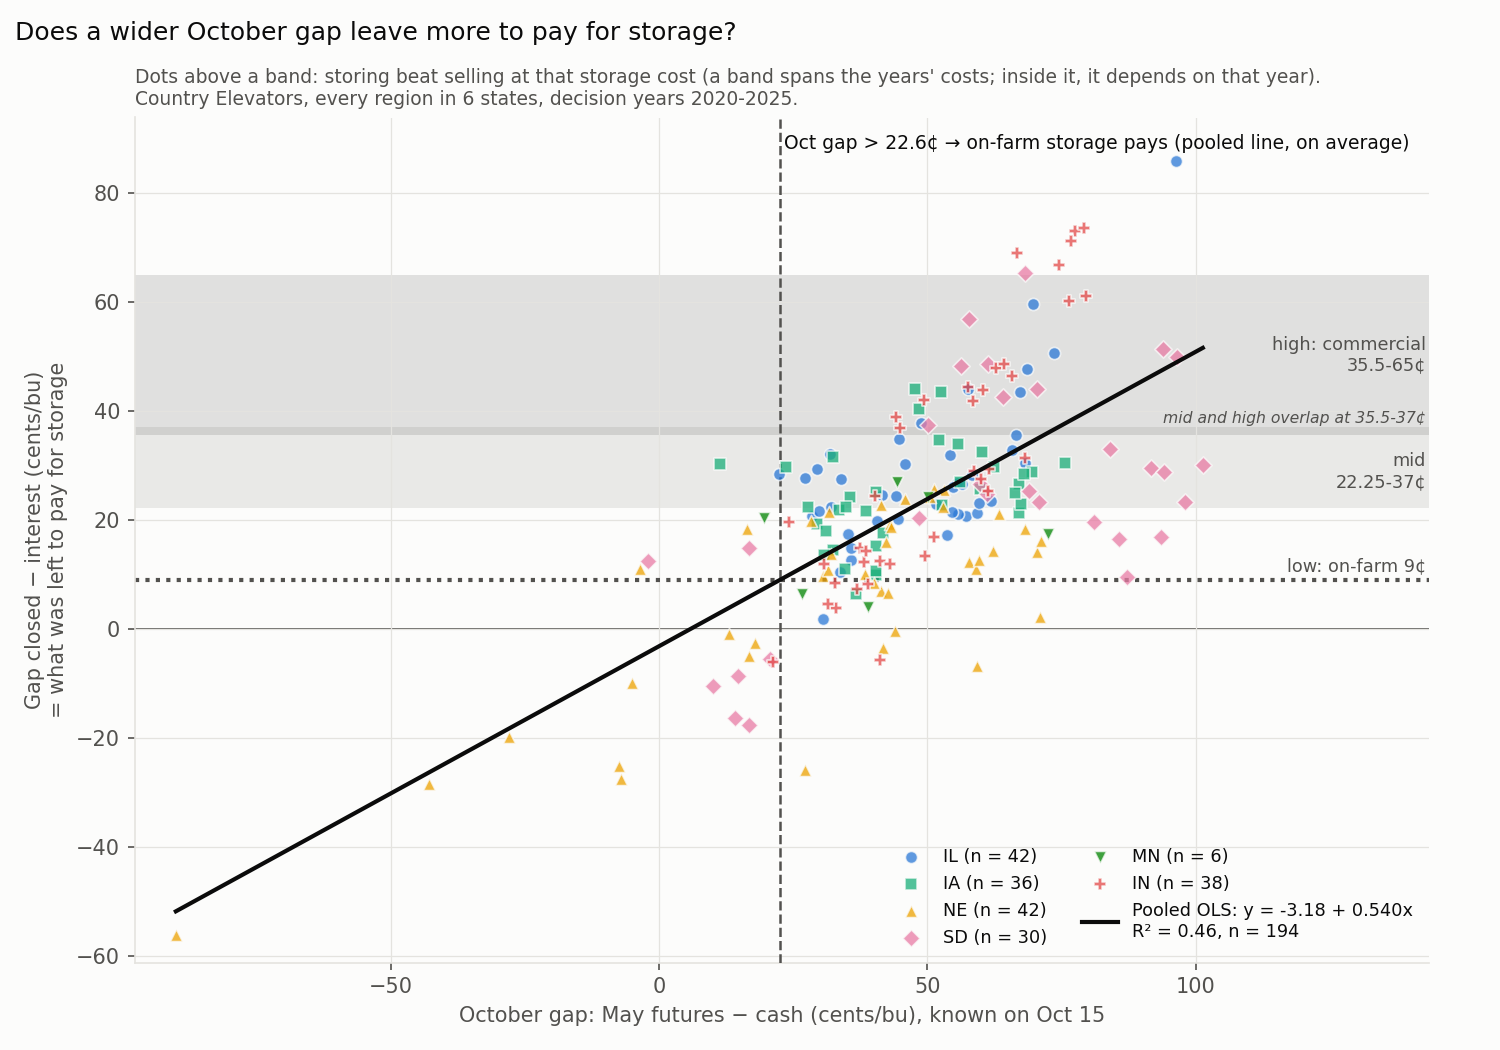

In [25]:
display(Image(filename=str(ROOT / "outputs/scatter_gap.png"), width=820))   # embed the current file in the notebook

### `outputs/bars_by_year.png`

One panel. Each bar is the **median** "left for storage" across all regions that year; the whisker spans the 10th to 90th
percentile, so it shows how different regions were. The step lines are the three storage costs (low dotted, mid dashed, high
solid). Under each year: the share of regions where storing won with low / mid / high storage cost, and the number of regions.
2021 was the weak year (median 9.7¢; storing won in only about half the regions even with on-farm storage), and 2023 the
strongest for on-farm storage (every region won). The 2023 jump in the mid and high lines is the commercial storage rate.

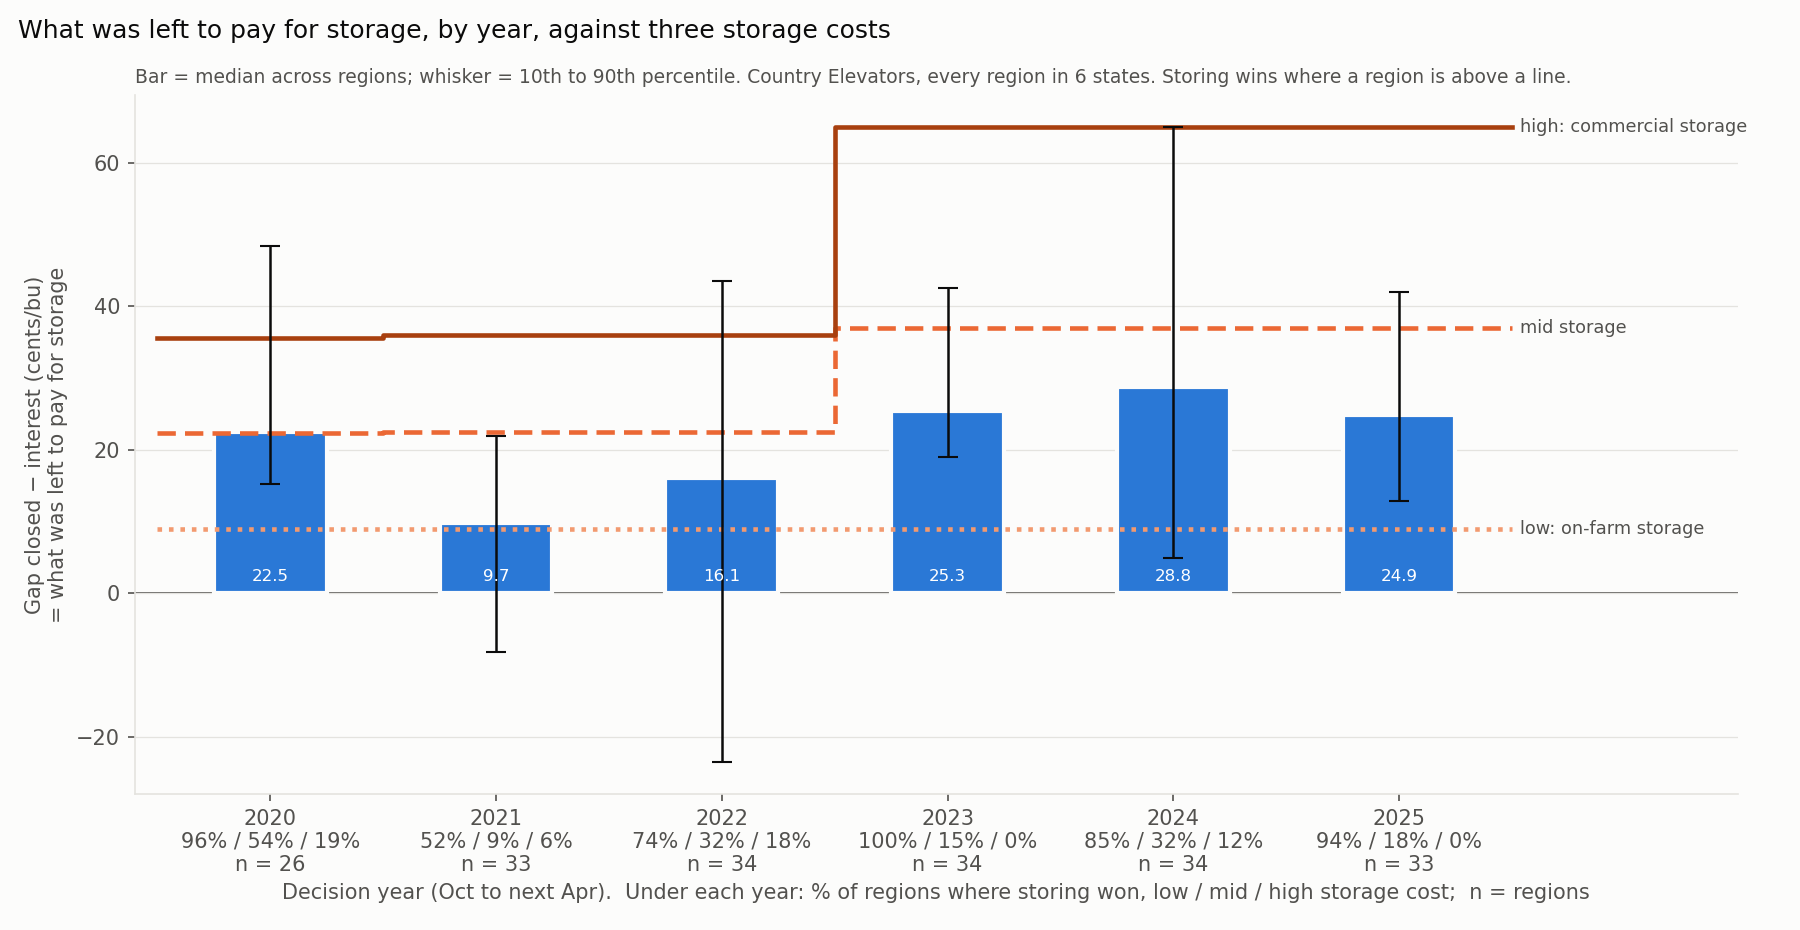

In [26]:
display(Image(filename=str(ROOT / "outputs/bars_by_year.png"), width=900))   # embed the current file in the notebook

*Details:* [processing log: 2026-11-21: all regions in 6 states (07, 08, 09 changed; rerun 03 → 09)](../docs/processing_log.md#2026-11-21-all-regions-in-6-states-07-08-09-changed-rerun-03--09) and [processing log: 08_charts.py: charts](../docs/processing_log.md#08_chartspy-charts)

# Part 5: Walk-forward test (`09_walk_forward.py`)

Part 4 fitted a line on **all** years, which describes the data but cheats as a forecast: in October 2023 nobody knew the
2024 result. The walk-forward test predicts each test year using **only earlier years**, then compares with what really
happened. All regions are pooled: every region-year of the training years goes into one fit.

| Round | Train on decision years | Training rows | Predict | Test rows | Last training result known by | Decision date |
|---|---|---|---|---|---|---|
| 1 | 2020-2022 | 93 | 2023 | 34 | Apr 2023 | Oct 13, 2023 |
| 2 | 2020-2023 | 127 | 2024 | 34 | Apr 2024 | Oct 15, 2024 |
| 3 | 2020-2024 | 161 | 2025 | 33 | Apr 2025 | Oct 15, 2025 |

**Why there is no leakage:** a training year's `gap_closed` is known on Apr 15 of the next calendar year, before the test
year's Oct 15. The test row's `gap_oct`, interest and storage cost are all known on its Oct 15 decision date. Every region in
a year shares the same futures and rate, so the regions are not independent: the 101 test rows are really 3 test years.

**a) Input: the gold table** (`09` reads `data/gold/gold_yearly.csv`).

In [27]:
show(gold)

194 rows x 34 columns


,decision_year,region_id,state,region,buyer_type,transport_mode,oct_date,oct_bid_date,oct_bid_date_lag_days,oct_cash,oct_futures,apr_date,apr_bid_date,apr_bid_date_lag_days,apr_cash,...,gap_closed_cents,interest_cents,breakeven_storage_cents,storage_low_cents,storage_mid_cents,storage_high_cents,hurdle_low_cents,hurdle_mid_cents,hurdle_high_cents,net_gain_low_cents,net_gain_mid_cents,net_gain_high_cents,store_wins_low,store_wins_mid,store_wins_high
0,2020,IA North Central,IA,North Central,Country Elevators,Truck,2020-10-15,2020-10-15,0,3.7575,4.0925,2021-04-15,2021-04-15,0,5.7860,...,22.10,0.222766,21.877234,9.0,22.25,35.5,9.222766,22.472766,35.722766,12.877234,-0.372766,-13.622766,True,False,False
1,2020,IA Northeast,IA,Northeast,Country Elevators,Truck,2020-10-15,2020-10-15,0,3.7686,4.0925,2021-04-15,2021-04-15,0,5.7233,...,14.72,0.223424,14.496576,9.0,22.25,35.5,9.223424,22.473424,35.723424,5.496576,-7.753424,-21.003424,True,False,False
2,2020,IA Northwest,IA,Northwest,Country Elevators,Truck,2020-10-15,2020-10-15,0,3.7975,4.0925,2021-04-15,2021-04-15,0,5.8000,...,19.50,0.225137,19.274862,9.0,22.25,35.5,9.225138,22.475137,35.725138,10.274862,-2.975138,-16.225138,True,False,False
3,2020,IA South Central,IA,South Central,Country Elevators,Truck,2020-10-15,2020-10-15,0,3.7361,4.0925,2021-04-15,2021-04-15,0,5.7886,...,24.50,0.221497,24.278503,9.0,22.25,35.5,9.221497,22.471497,35.721497,15.278503,2.028503,-11.221497,True,True,False
4,2020,IA Southeast,IA,Southeast,Country Elevators,Truck,2020-10-15,2020-10-15,0,3.7818,4.0925,2021-04-15,2021-04-15,0,5.7714,...,18.21,0.224207,17.985793,9.0,22.25,35.5,9.224207,22.474207,35.724207,8.985793,-4.264207,-17.514207,True,False,False


missing per column: none


**b) Forecast, decision and scoring code.** `09_walk_forward.py` **lines 42-65** (forecasts), **lines 69-74** (decisions)
and **lines 79-90** (scoreboard); shortened to fewer stored columns.

- **Two forecasts of `gap_closed`** for each test row: **regression** (fit `gap_closed ~ gap_oct` on the training rows,
  apply it to the test row's `gap_oct`) and **past average** (mean `gap_closed` of the training rows).
- **Rule** for storage case c: **store if forecast − interest > storage_c**, otherwise sell. Every input is known on Oct 15.
- **Score:** a stored row earns its real `net_gain_c`; a sold row earns 0. A **correct call** matches hindsight (store if the
  real net gain was > 0). MAE = average size of the forecast miss, in cents/bu.

In [28]:
rows = []                                                                      # one row per test row
for rnd, test_year in enumerate([2023, 2024, 2025], start=1):                  # line 42: 3 rounds
    train = gold[gold["decision_year"] < test_year]                            # line 43: ONLY earlier years
    test = gold[gold["decision_year"] == test_year]                            # line 44: the year to predict
    slope, intercept = np.polyfit(train["gap_oct_cents"], train["gap_closed_cents"], 1)   # line 46: OLS on training rows
    avg = train["gap_closed_cents"].mean()                                     # line 47: past-average forecast
    print(f"round {rnd}: train {len(train)} rows → {test_year} ({len(test)} rows): "
          f"intercept {intercept:.2f}, slope {slope:.3f}, past average {avg:.2f}")
    for _, r in test.iterrows():                                               # lines 51-63: each test row
        rows.append({"round": rnd, "test_year": test_year, "region_id": r["region_id"],
                     "actual": r["gap_closed_cents"],                          # what really closed
                     "pred_regression": intercept + slope * r["gap_oct_cents"],   # line applied to this Oct gap
                     "pred_past_average": avg, "interest": r["interest_cents"],
                     **{f"storage_{c}": r[f"storage_{c}_cents"] for c in CASES},
                     **{f"net_gain_{c}": r[f"net_gain_{c}_cents"] for c in CASES}})
pred = pd.DataFrame(rows)
mae = {m: (pred[f"pred_{m}"] - pred["actual"]).abs().mean() for m in ["regression", "past_average"]}   # lines 65-66, 100-101
print(f"MAE over {len(pred)} test rows: regression {mae['regression']:.2f}, past average {mae['past_average']:.2f}"
      "  (log: 13.19 vs 16.24)")
score = []                                                                     # lines 79-90: scoreboard rows
for c in CASES:                                                                # each storage case
    best = pred[f"net_gain_{c}"] > 0                                           # line 71: hindsight best = store?
    calls = {"always sell": pd.Series(False, index=pred.index),                 # never store
             "always store": pd.Series(True, index=pred.index),                # store every year
             "past average": pred["pred_past_average"] - pred["interest"] > pred[f"storage_{c}"],   # line 73
             "regression": pred["pred_regression"] - pred["interest"] > pred[f"storage_{c}"]}       # line 74
    for s, store in calls.items():                                             # each strategy
        net = np.where(store, pred[f"net_gain_{c}"], 0.0)                      # line 84: real gain if stored, else 0
        score.append({"storage_case": c, "strategy": s, "times_stored": int(store.sum()),
                      "total_net_gain_cents": round(net.sum(), 2),             # line 87
                      "correct_calls": int((store == best).sum())})            # line 90
score = pd.DataFrame(score)

round 1: train 93 rows → 2023 (34 rows): intercept -0.34, slope 0.687, past average 21.38
round 2: train 127 rows → 2024 (34 rows): intercept 0.63, slope 0.668, past average 26.38
round 3: train 161 rows → 2025 (33 rows): intercept -0.31, slope 0.671, past average 29.07
MAE over 101 test rows: regression 13.19, past average 16.24  (log: 13.19 vs 16.24)


**c) Scoreboard:** total net gain over the 101 test rows (cents/bu, summed over regions) and correct calls, per storage
case and strategy.

In [29]:
n_test = len(pred)
show(score.pivot(index="storage_case", columns="strategy", values="total_net_gain_cents").loc[list(CASES)].round(1).astype(str)
     + " (" + score.pivot(index="storage_case", columns="strategy", values="correct_calls").loc[list(CASES)].astype(str) + f"/{n_test})")
print("matches outputs/scoreboard.csv:", np.allclose(score["total_net_gain_cents"], scoreboard["total_net_gain_cents"], atol=0.01)
      and score["correct_calls"].eq(scoreboard["correct_calls"]).all())

3 rows x 4 columns


strategy,always sell,always store,past average,regression
storage_case,,,,
low,0.0 (7/101),1917.8 (94/101),1744.5 (83/101),1896.5 (92/101)
mid,0.0 (79/101),-910.2 (22/101),0.0 (79/101),-102.3 (66/101)
high,0.0 (97/101),-3738.2 (4/101),0.0 (97/101),0.0 (97/101)


missing per column: none
matches outputs/scoreboard.csv: True


**Results in short** (101 test rows = 34 + 34 + 33 regions in 2023-2025):
- **Accuracy:** the regression missed by less on average (MAE **13.19** vs **16.24** cents/bu). With many regions in the
  training data, every round's line has a positive slope of about 0.67 (the old Illinois-only round 1, fitted on 6 points,
  had a negative slope).
- **On-farm storage (low):** *always store* earned the most (**+1,917.8¢** in total, about +19.0¢ per test row, 94/101 correct
  calls). The regression was close (+1,896.5¢, 92/101): it said sell only twice. The past average did worst of the three
  (+1,744.5¢, 83/101): in 2023 its forecast (21.4¢) sat just below the hurdle (interest + 9¢ = 20.2-22.0¢), so it said **sell** in
  11 regions that would all have gained (173.3¢ missed in total).
- **Mid cost:** storing every year lost **−910.2¢**. The past average never stored (0, 79/101 correct). The regression stored
  35 times, won only 11 of them, and lost **−102.3¢** in total (66/101).
- **Commercial cost (high):** always storing lost **−3,738.2¢**; both forecast rules always said sell (0, 97/101 correct).
- **Lesson:** a more accurate forecast does not guarantee better decisions. Only errors near the hurdle change the call: the
  regression's edge helped in the low case and hurt in the mid case.

*Details:* [processing log: 2026-11-21: all regions in 6 states (07, 08, 09 changed; rerun 03 → 09)](../docs/processing_log.md#2026-11-21-all-regions-in-6-states-07-08-09-changed-rerun-03--09) and [processing log: 2026-11-13: 09 walk-forward test (first out-of-sample results)](../docs/processing_log.md#2026-11-13-09-walk-forward-test-first-out-of-sample-results) (the Illinois-only results)

# Part 6: Wrap-up

## What this means

- **Storage cost still decides the answer.** Across 194 region-years in six states, a hedged storage beat selling at harvest
  in 161 (83%) with on-farm storage, 50 (26%) at the mid cost and only 17 (9%) at commercial elevator rates.
- **The October gap is a real but noisy clue.** A wider October gap left more to pay for storage (pooled slope 0.54,
  R² 0.46), and the pattern holds within states (slope 0.49 with state effects). States differ in level: Nebraska and South
  Dakota left noticeably less than Illinois for the same gap.
- **For on-farm storage, "always store" was hard to beat.** In the 2023-2025 test it earned the most; the regression came
  close and the past average lost money by saying sell near the hurdle. At mid and commercial costs, staying out was right,
  and the regression's extra accuracy led it to store at the wrong times.

## Limits and next steps

- **Few years:** 6 decision years and 3 test years. The 34 regions add rows but not independent years: every region shares
  the same futures, rate and weather year. **More years** (back to 2010) need another source, because the USDA API starts in mid-2020.
- **Storage-cost assumptions:** the same costs are used in every state: the commercial (high) cost is one Ohio elevator's
  yearly rate halved, which probably understates a 6-month hold (about 68% of the yearly cost, not 50%); the on-farm (low)
  cost is a single 2016 Iowa range, the same every year; 2025 high is carried forward from 2024. Shrink, commissions and
  margin interest are ignored.
- **Data quirks:** Nebraska 2022 cash bids above futures (real, but extreme); Indiana's weekly months use bids up to 5 days
  before the futures date; Indiana has no 2020 data; Minnesota is one region.
- **Apr-vs-Oct basis check:** compare the April basis with the October basis directly, not only their difference, to
  see whether storing gains come from a weak October or a strong April.